In [1]:
import numpy as np
import pandas as pd

In [2]:

# Load features
A_array_loaded = pd.read_csv('A_2.csv').to_numpy()
B_array_loaded = pd.read_csv('B_2.csv').to_numpy()
C_array_loaded = pd.read_csv('C_2.csv').to_numpy()
D_array_loaded = pd.read_csv('D_2.csv').to_numpy()

# shapes
print("A_array:", A_array_loaded.shape)
print("B_array:", B_array_loaded.shape)
print("C_array:", C_array_loaded.shape)
print("D_array:", D_array_loaded.shape)


A_array: (41, 23)
B_array: (635, 23)
C_array: (5954, 23)
D_array: (993, 23)


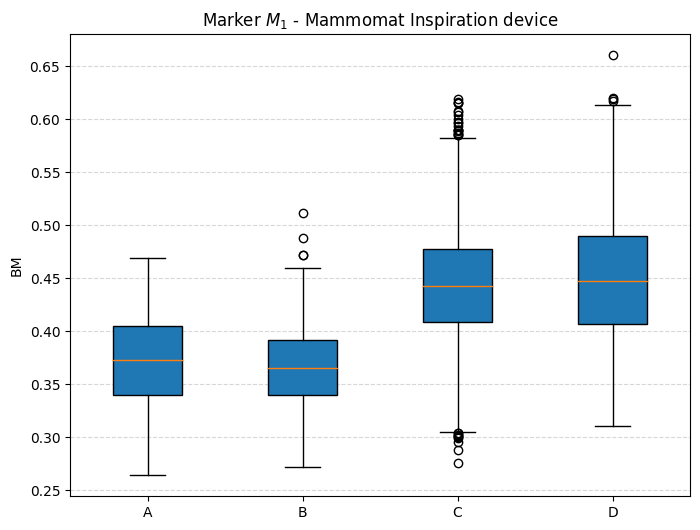

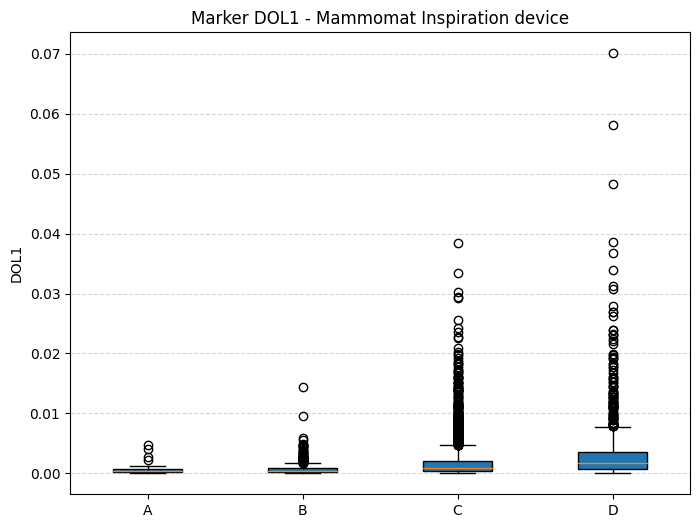

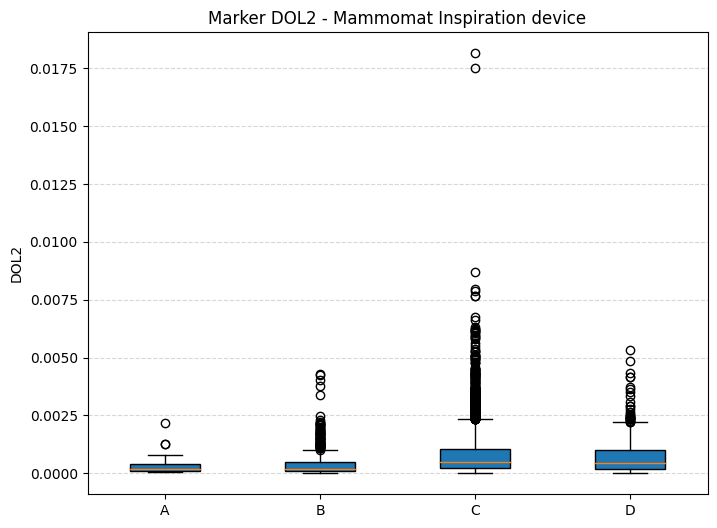

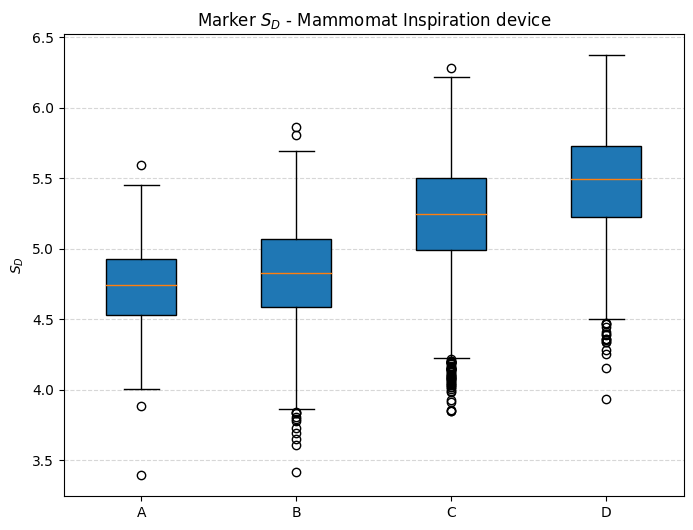

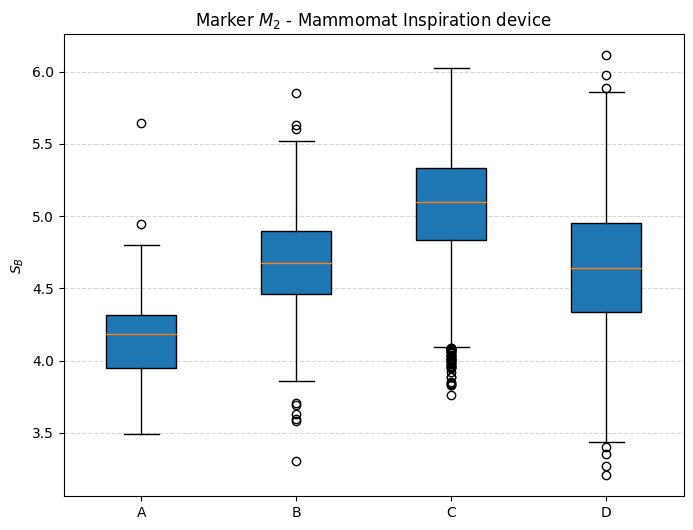

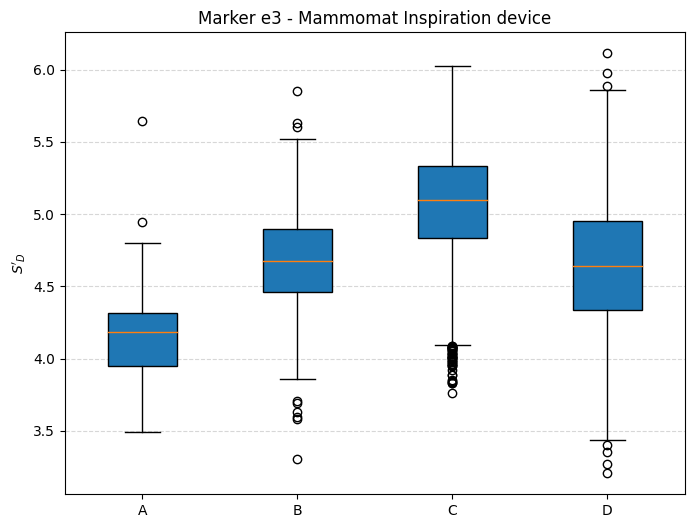

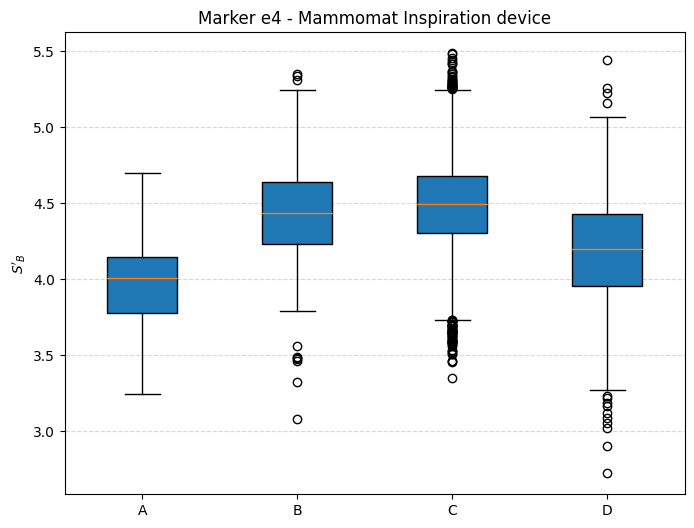

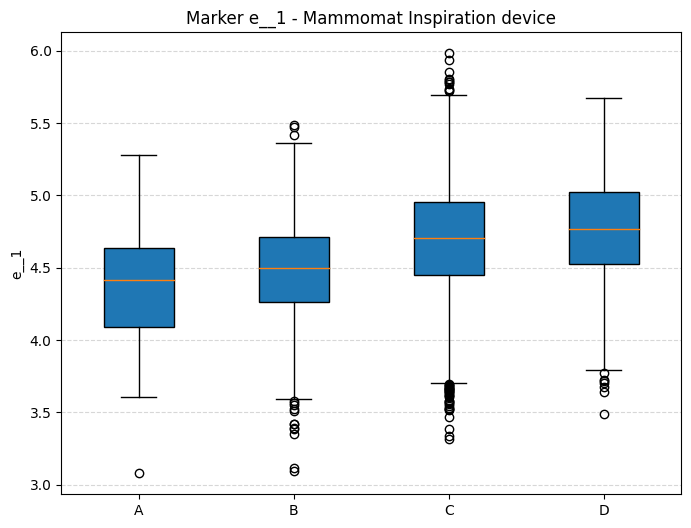

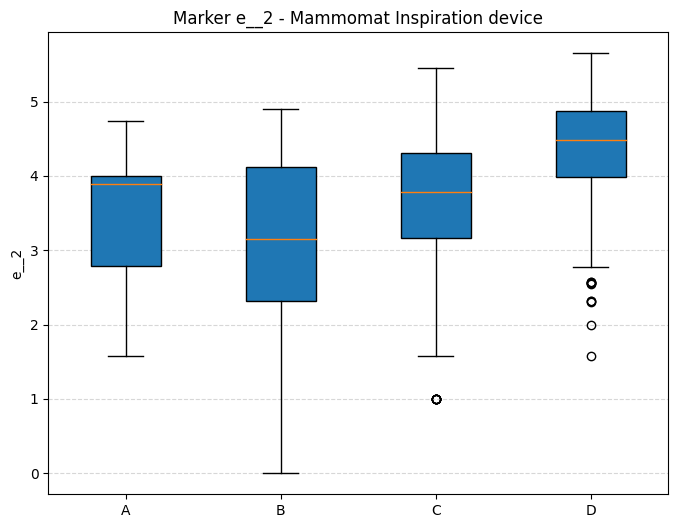

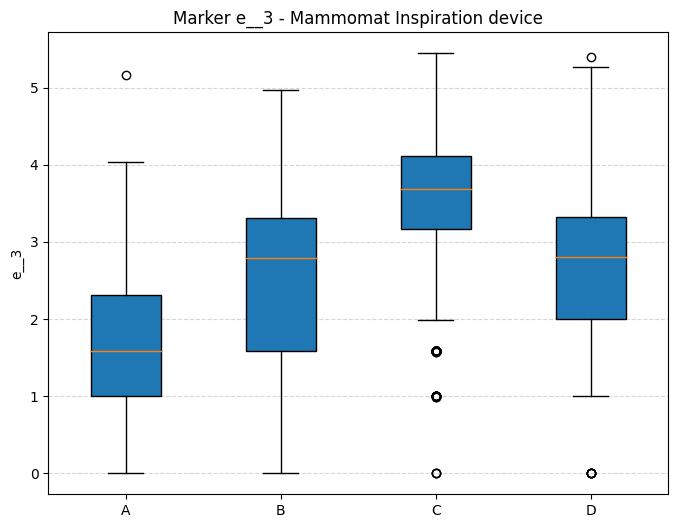

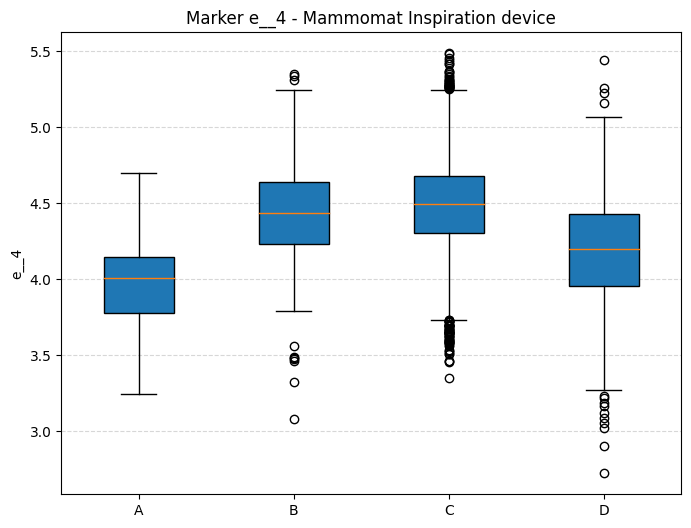

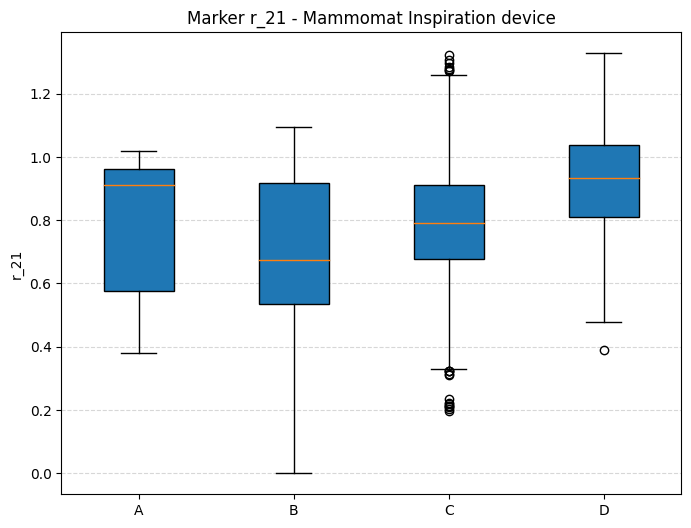

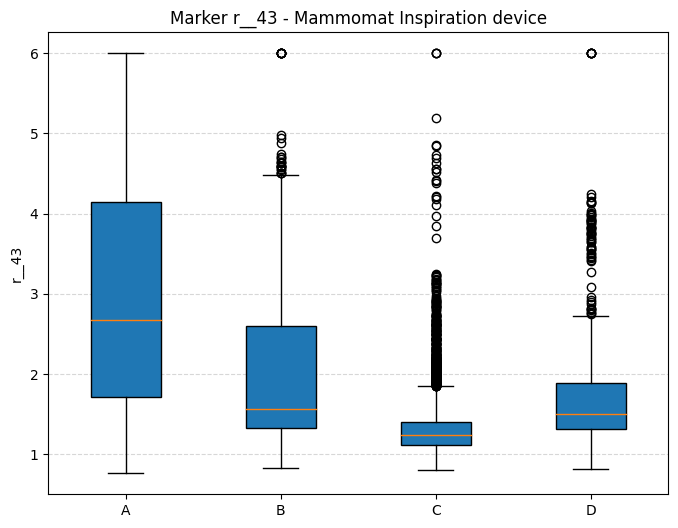

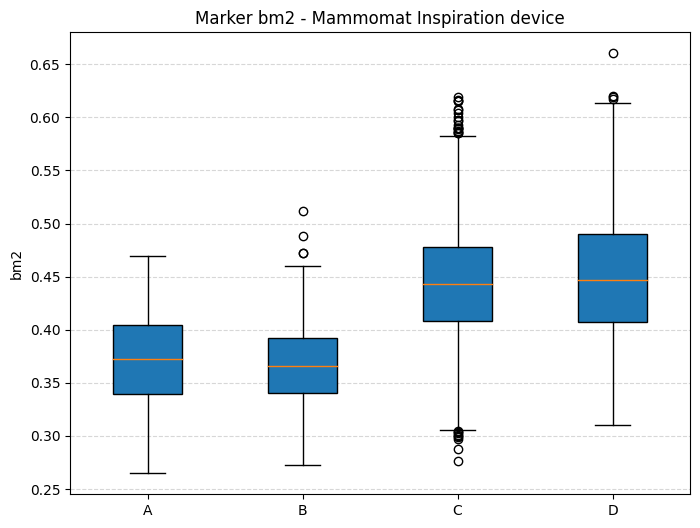

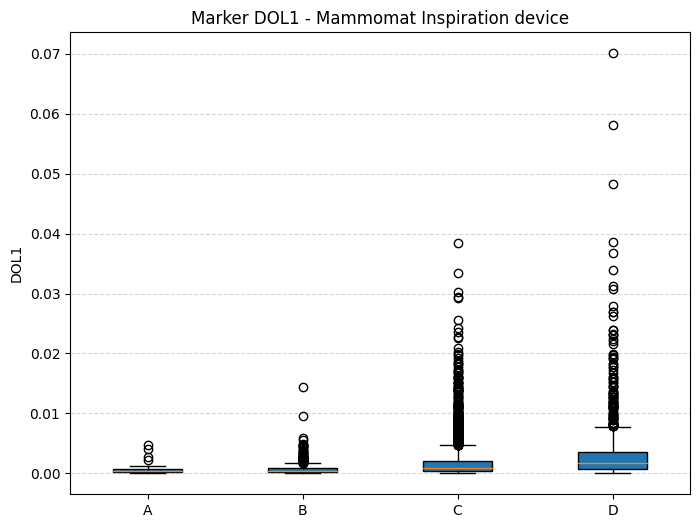

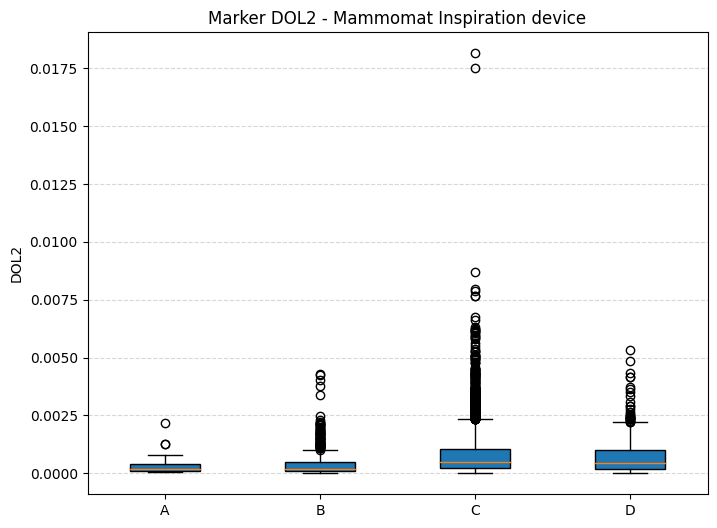

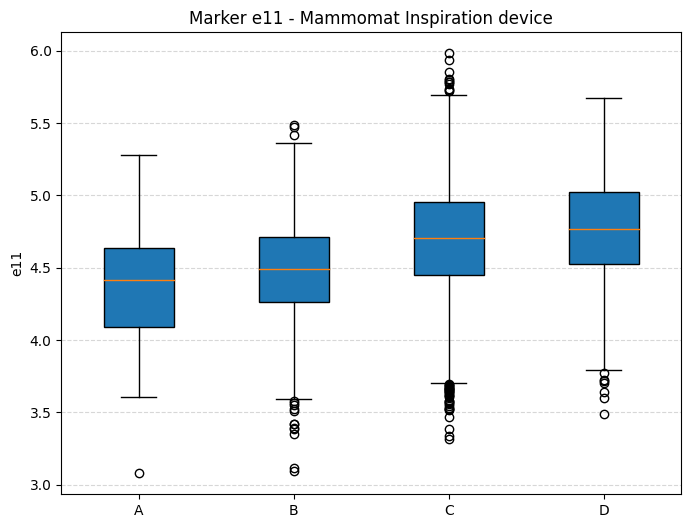

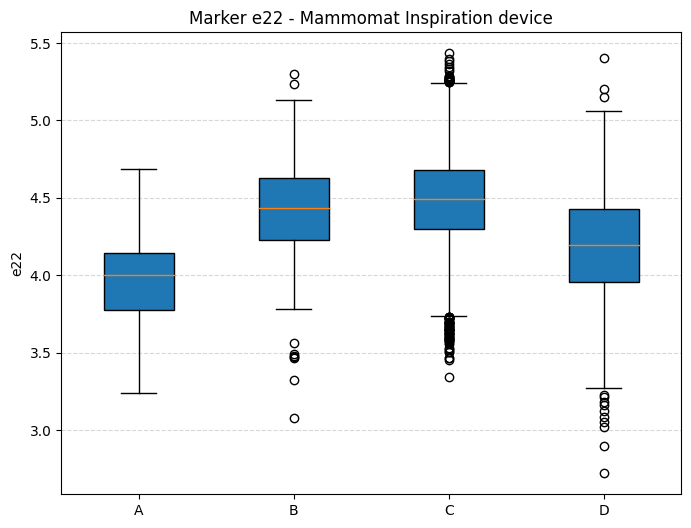

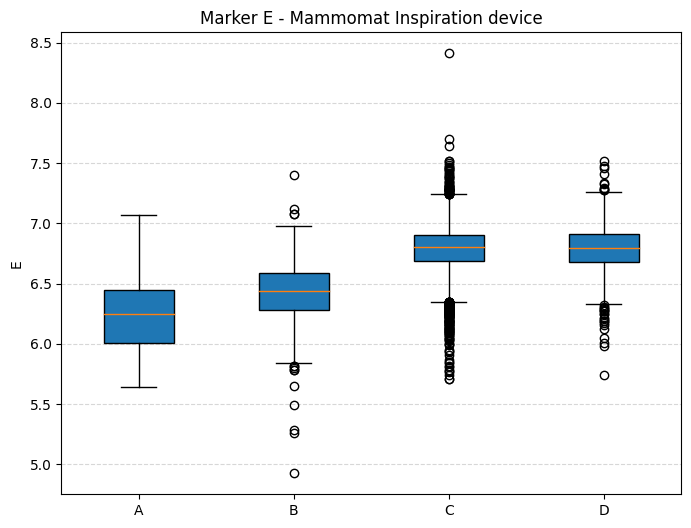

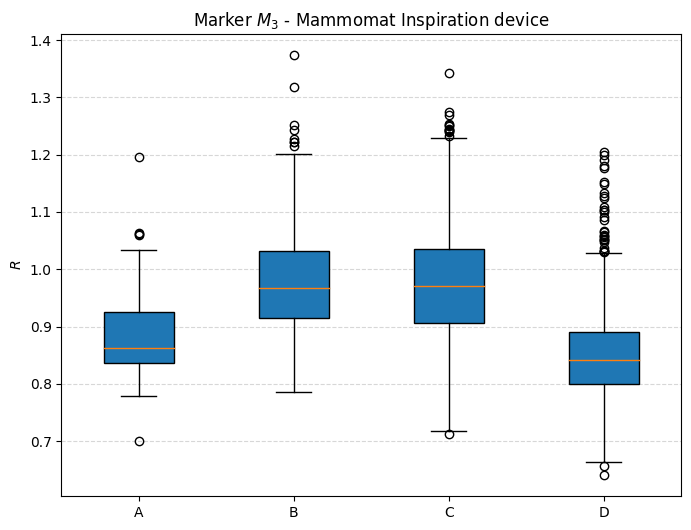

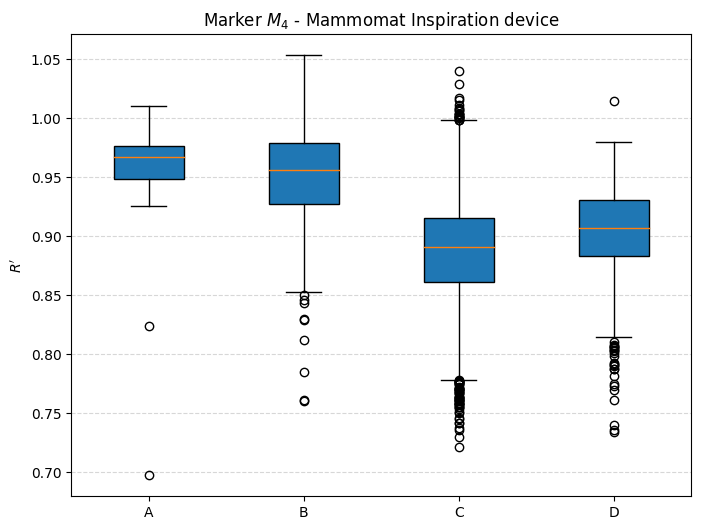

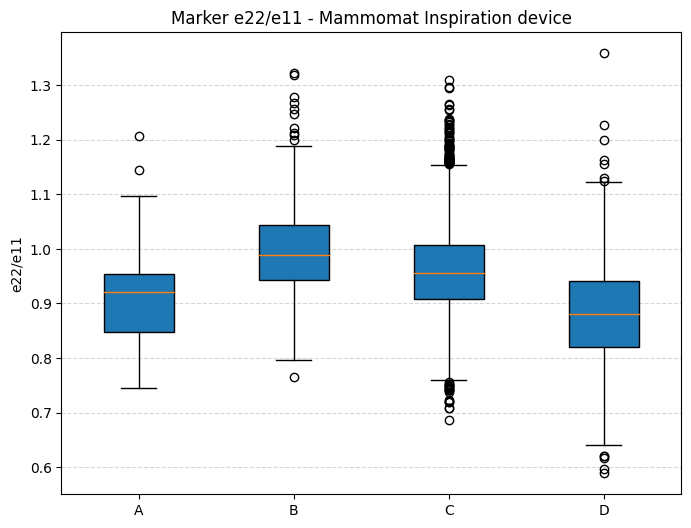

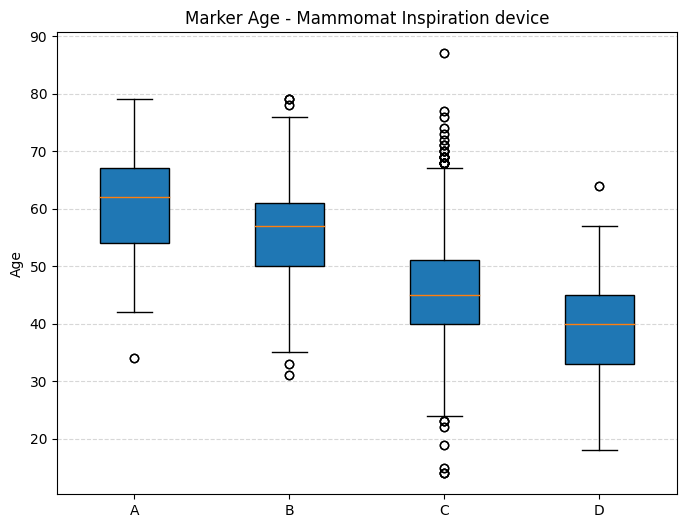

In [3]:
import matplotlib.pyplot as plt

feature_names = [
    "BM", "DOL1", "DOL2", "$S_D$", "$S_B$", "$S'_D$", "$S'_B$", "e__1", "e__2", "e__3", "e__4",
    "r_21", "r__43", "bm2", "DOL1", "DOL2", "e11", "e22", "E", "$R$", "$R'$", "e22/e11", "Age"
]
feature_names_1 = [
    "$M_1$", "DOL1", "DOL2", "$S_D$", "$M_2$", "e3", "e4", "e__1", "e__2", "e__3", "e__4",
    "r_21", "r__43", "bm2", "DOL1", "DOL2", "e11", "e22", "E", "$M_3$", "$M_4$", "e22/e11", "Age"
]

# Ensure A, B, C, D exist and have correct shape
num_features = len(feature_names)
assert A_array_loaded.shape[1] >= num_features, "Not enough columns in A, B, C, or D arrays."

# Loop through each feature
for i, name in enumerate(feature_names):
    plt.figure(figsize=(8, 6))
    plt.boxplot([A_array_loaded[:, i], B_array_loaded[:, i], C_array_loaded[:, i], D_array_loaded[:, i]], 
                labels=['A', 'B', 'C', 'D'], patch_artist=True)
    plt.title(f"Marker {feature_names_1[i]} - Mammomat Inspiration device")
    plt.ylabel(name)
    plt.grid(axis='y', linestyle='--', alpha=0.5)
    plt.show()


In [4]:
feature_names[2]

'DOL2'

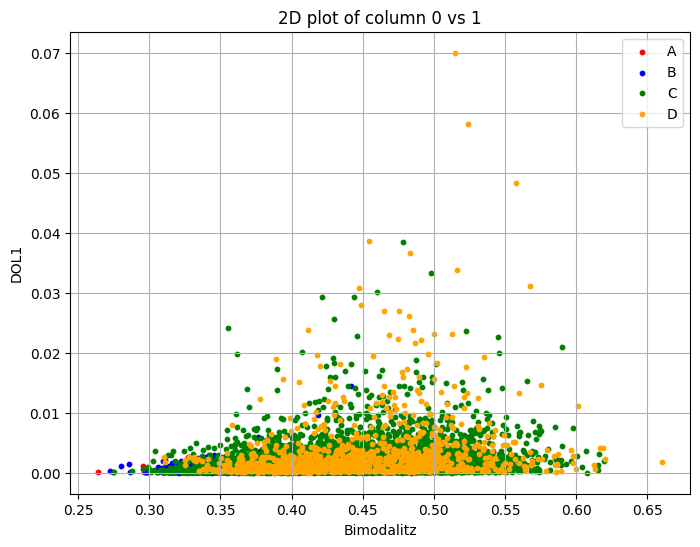

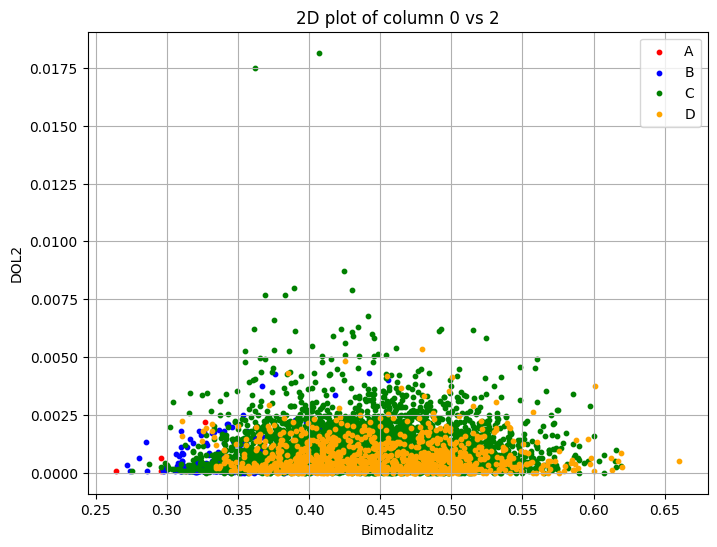

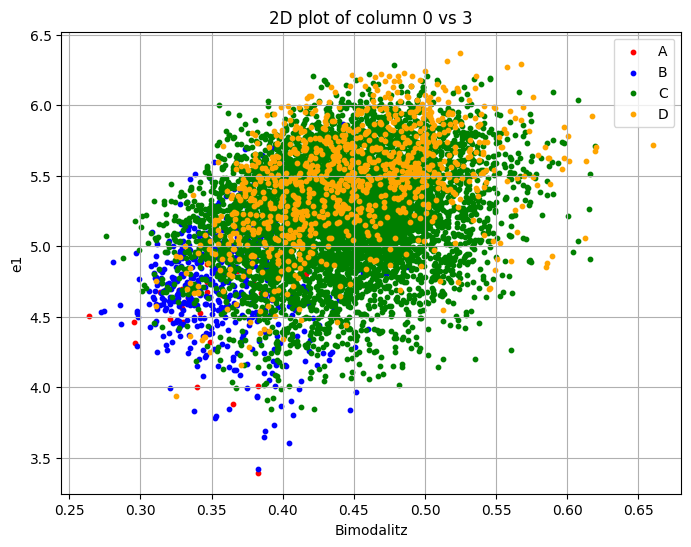

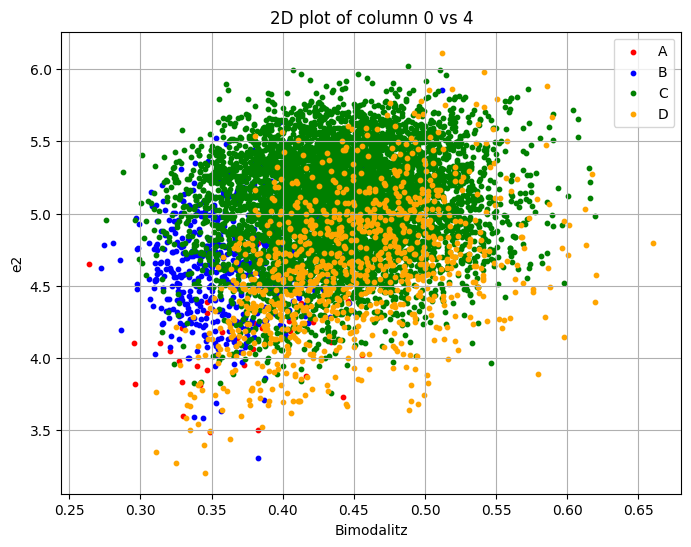

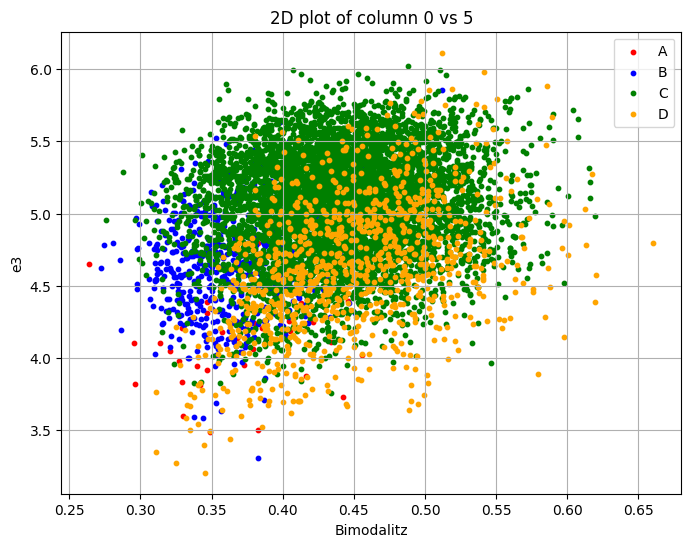

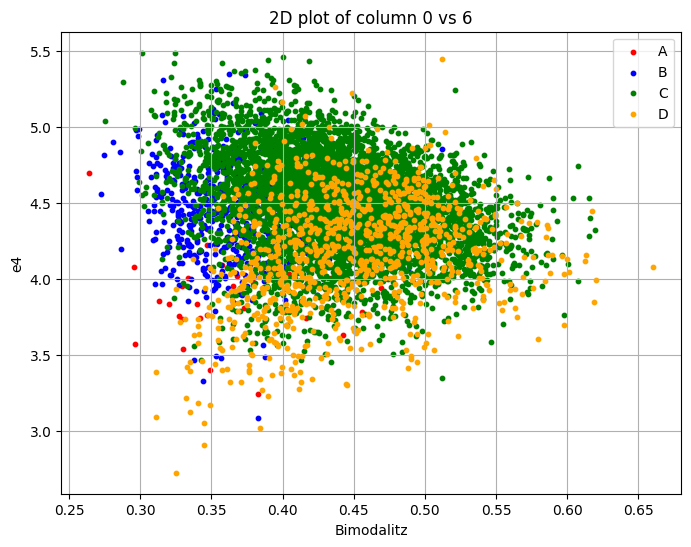

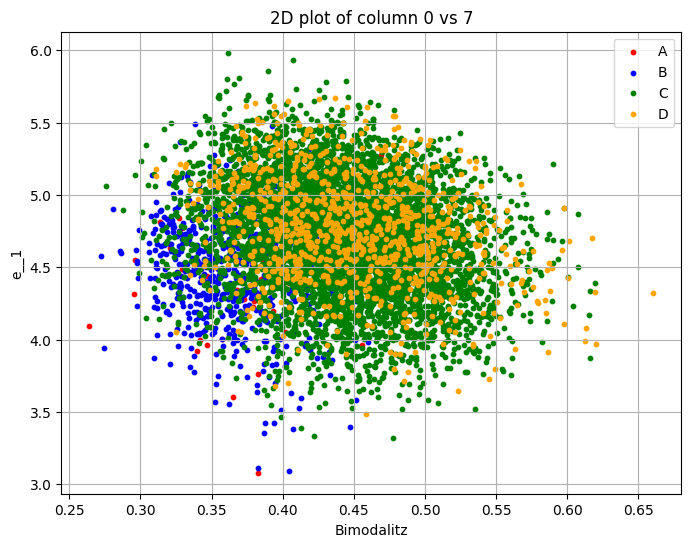

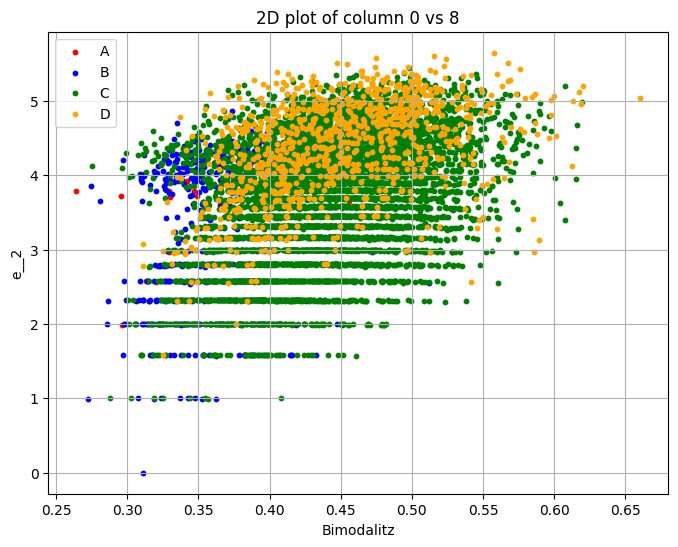

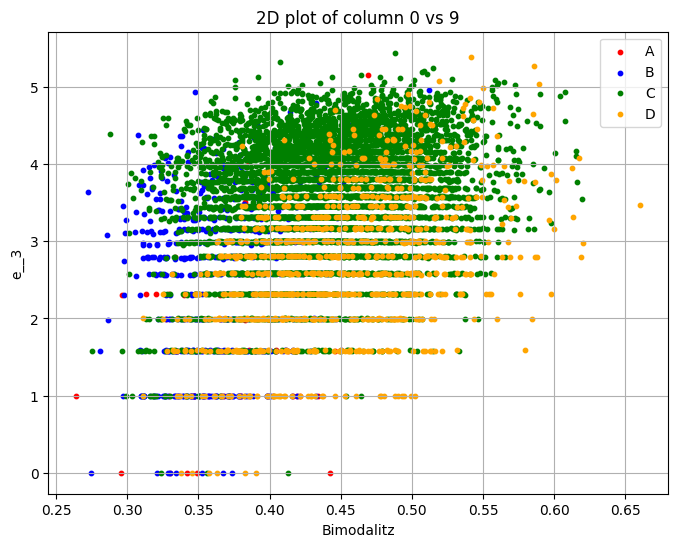

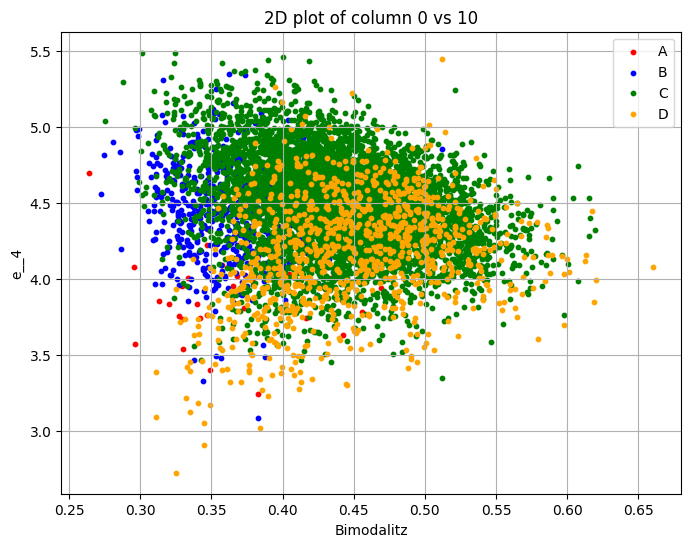

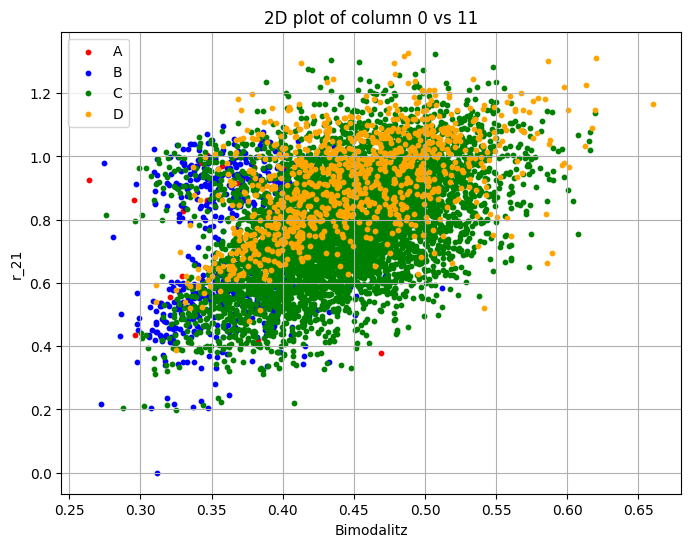

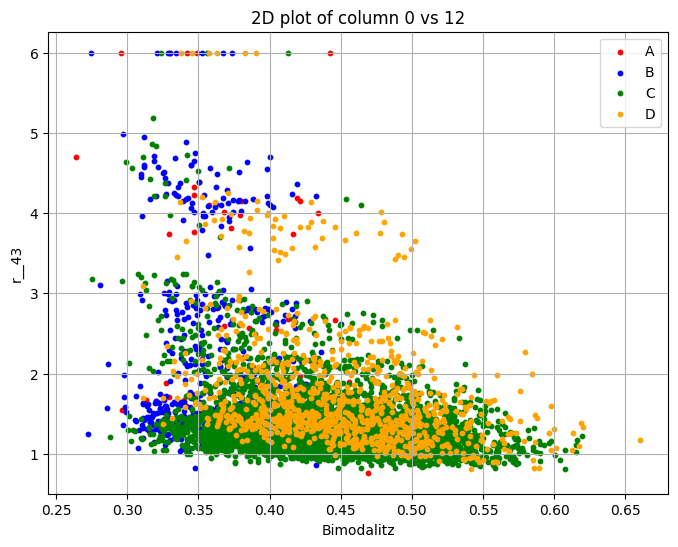

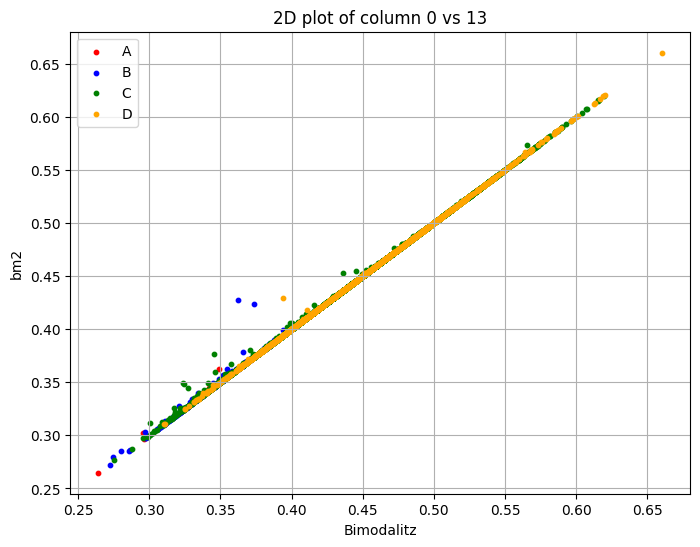

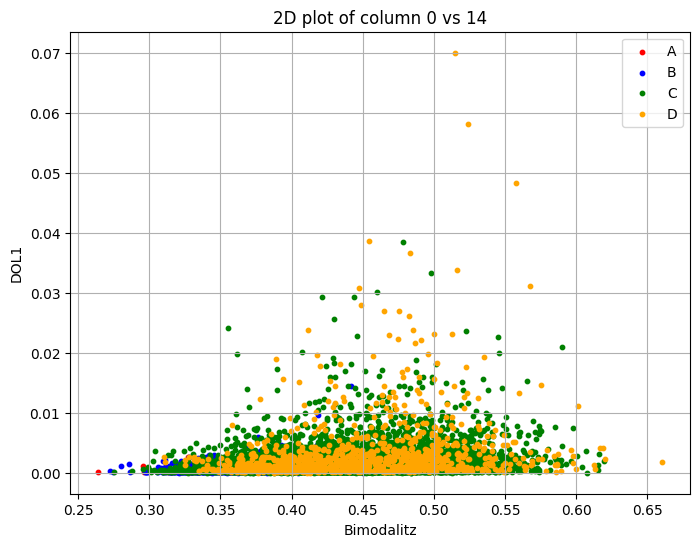

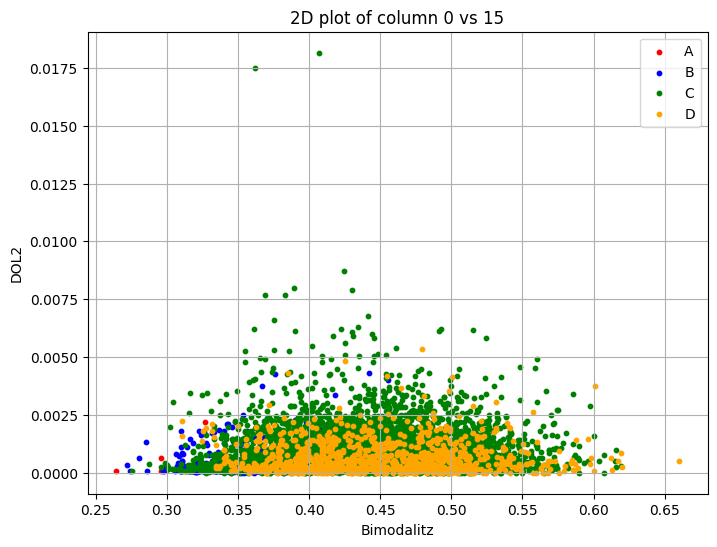

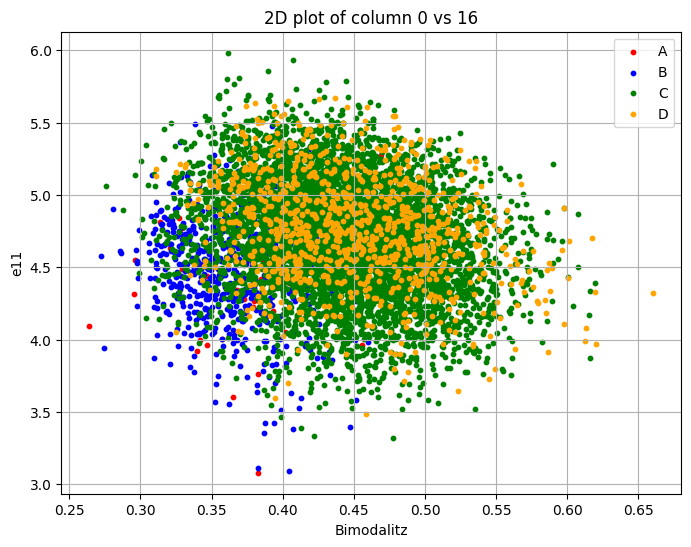

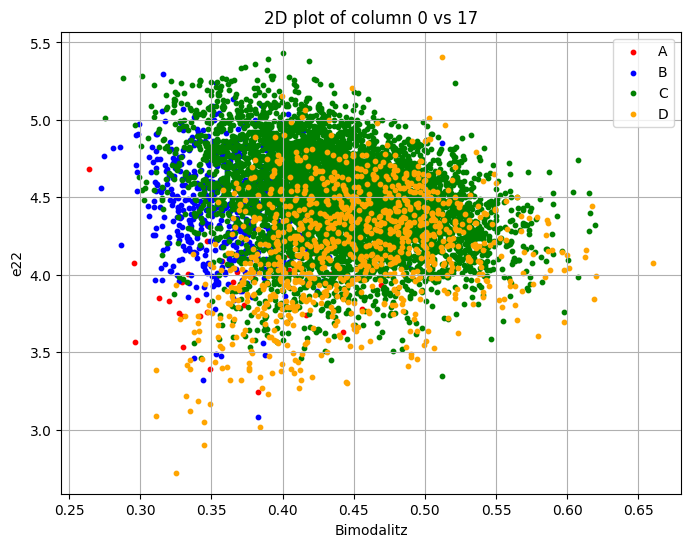

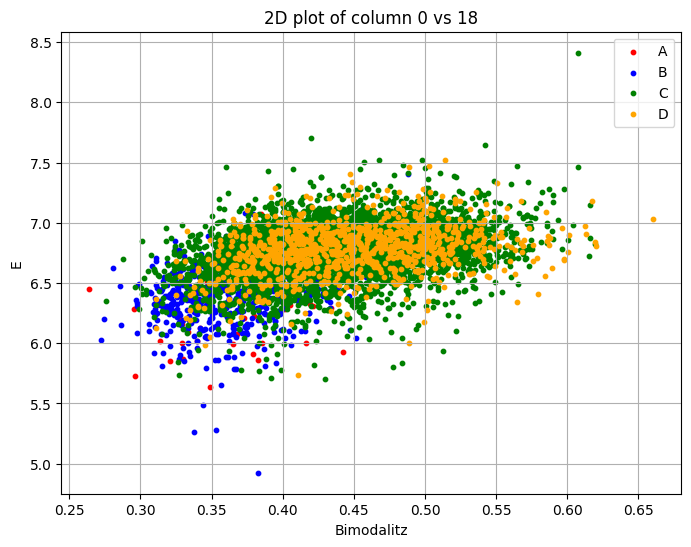

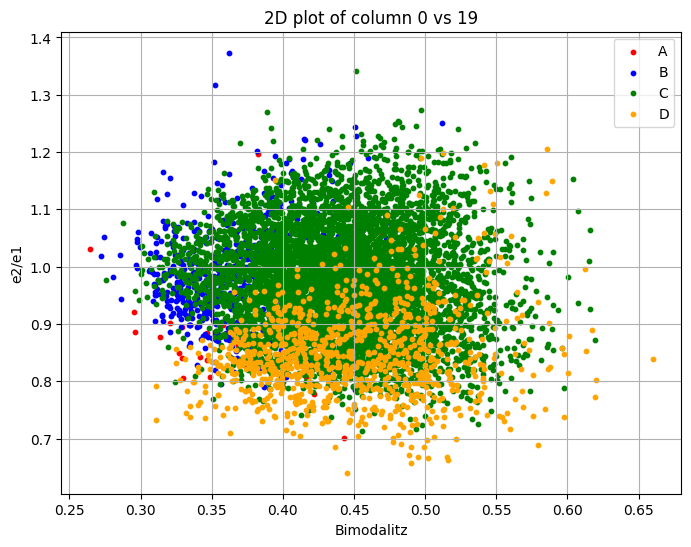

In [5]:
for i in range(1, 20):
    plt.figure(figsize=(8,6))
    
    #  M1 vs Mi for each array
    plt.scatter(A_array_loaded[:, 0], A_array_loaded[:, i], color='red', label='A', s=10)
    plt.scatter(B_array_loaded[:, 0], B_array_loaded[:, i], color='blue', label='B', s=10)
    plt.scatter(C_array_loaded[:, 0], C_array_loaded[:, i], color='green', label='C', s=10)
    plt.scatter(D_array_loaded[:, 0], D_array_loaded[:, i], color='orange', label='D', s=10)
    
    plt.xlabel('Bimodalitz')
    plt.ylabel(f"{feature_names[i]}")
    plt.title(f'2D plot of column 0 vs {i}')
    plt.legend()
    plt.grid(True)
    plt.show()


In [6]:
import tensorflow as tf
from tensorflow.keras import layers, models
from tensorflow.keras.callbacks import ModelCheckpoint
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from tensorflow.keras.utils import to_categorical
from sklearn.metrics import confusion_matrix, classification_report, ccuracy_score, roc_auc_score, f1_score, confusion_matrix, recall_score
from tensorflow.keras import backend as K
from sklearn.model_selection import StratifiedKFold

import seaborn as sns
from scipy import stats

## 5 fold validation for 2, 3 and 4 class for just 16 neurons (500 runs)


## A|B|C|D


   RUN 1/100
Run 1 | Fold 1: ACC=0.834, AUC=0.893, F1=0.820, SEN=0.834
Run 1 | Fold 2: ACC=0.843, AUC=0.906, F1=0.821, SEN=0.843
Run 1 | Fold 3: ACC=0.819, AUC=0.891, F1=0.804, SEN=0.819
Run 1 | Fold 4: ACC=0.844, AUC=0.913, F1=0.829, SEN=0.844
Run 1 | Fold 5: ACC=0.825, AUC=0.870, F1=0.806, SEN=0.825

   RUN 2/100
Run 2 | Fold 1: ACC=0.838, AUC=0.896, F1=0.820, SEN=0.838
Run 2 | Fold 2: ACC=0.835, AUC=0.904, F1=0.814, SEN=0.835
Run 2 | Fold 3: ACC=0.816, AUC=0.891, F1=0.799, SEN=0.816
Run 2 | Fold 4: ACC=0.846, AUC=0.917, F1=0.835, SEN=0.846
Run 2 | Fold 5: ACC=0.823, AUC=0.866, F1=0.811, SEN=0.823

   RUN 3/100
Run 3 | Fold 1: ACC=0.845, AUC=0.902, F1=0.821, SEN=0.845
Run 3 | Fold 2: ACC=0.832, AUC=0.905, F1=0.802, SEN=0.832
Run 3 | Fold 3: ACC=0.810, AUC=0.894, F1=0.794, SEN=0.810
Run 3 | Fold 4: ACC=0.839, AUC=0.914, F1=0.826, SEN=0.839
Run 3 | Fold 5: ACC=0.827, AUC=0.856, F1=0.807, SEN=0.827

   RUN 4/100
Run 4 | Fold 1: ACC=0.839, AUC=0.898, F1=0.823, SEN=0.839
Run 4 | Fold 2: 

Run 24 | Fold 1: ACC=0.839, AUC=0.898, F1=0.822, SEN=0.839
Run 24 | Fold 2: ACC=0.837, AUC=0.910, F1=0.821, SEN=0.837
Run 24 | Fold 3: ACC=0.814, AUC=0.896, F1=0.800, SEN=0.814
Run 24 | Fold 4: ACC=0.843, AUC=0.911, F1=0.825, SEN=0.843
Run 24 | Fold 5: ACC=0.820, AUC=0.859, F1=0.806, SEN=0.820

   RUN 25/100
Run 25 | Fold 1: ACC=0.836, AUC=0.901, F1=0.815, SEN=0.836
Run 25 | Fold 2: ACC=0.830, AUC=0.909, F1=0.824, SEN=0.830
Run 25 | Fold 3: ACC=0.818, AUC=0.889, F1=0.796, SEN=0.818
Run 25 | Fold 4: ACC=0.851, AUC=0.915, F1=0.838, SEN=0.851
Run 25 | Fold 5: ACC=0.828, AUC=0.865, F1=0.808, SEN=0.828

   RUN 26/100
Run 26 | Fold 1: ACC=0.837, AUC=0.897, F1=0.822, SEN=0.837
Run 26 | Fold 2: ACC=0.833, AUC=0.905, F1=0.822, SEN=0.833
Run 26 | Fold 3: ACC=0.822, AUC=0.894, F1=0.801, SEN=0.822
Run 26 | Fold 4: ACC=0.855, AUC=0.907, F1=0.845, SEN=0.855
Run 26 | Fold 5: ACC=0.823, AUC=0.872, F1=0.800, SEN=0.823

   RUN 27/100
Run 27 | Fold 1: ACC=0.835, AUC=0.895, F1=0.819, SEN=0.835
Run 27 | Fo

Run 47 | Fold 1: ACC=0.836, AUC=0.897, F1=0.818, SEN=0.836
Run 47 | Fold 2: ACC=0.841, AUC=0.905, F1=0.817, SEN=0.841
Run 47 | Fold 3: ACC=0.820, AUC=0.893, F1=0.804, SEN=0.820
Run 47 | Fold 4: ACC=0.850, AUC=0.913, F1=0.834, SEN=0.850
Run 47 | Fold 5: ACC=0.819, AUC=0.865, F1=0.805, SEN=0.819

   RUN 48/100
Run 48 | Fold 1: ACC=0.835, AUC=0.903, F1=0.818, SEN=0.835
Run 48 | Fold 2: ACC=0.833, AUC=0.906, F1=0.806, SEN=0.833
Run 48 | Fold 3: ACC=0.818, AUC=0.892, F1=0.800, SEN=0.818
Run 48 | Fold 4: ACC=0.847, AUC=0.913, F1=0.833, SEN=0.847
Run 48 | Fold 5: ACC=0.820, AUC=0.865, F1=0.808, SEN=0.820

   RUN 49/100
Run 49 | Fold 1: ACC=0.838, AUC=0.908, F1=0.812, SEN=0.838
Run 49 | Fold 2: ACC=0.832, AUC=0.907, F1=0.819, SEN=0.832
Run 49 | Fold 3: ACC=0.815, AUC=0.895, F1=0.798, SEN=0.815
Run 49 | Fold 4: ACC=0.841, AUC=0.916, F1=0.831, SEN=0.841
Run 49 | Fold 5: ACC=0.823, AUC=0.865, F1=0.802, SEN=0.823

   RUN 50/100
Run 50 | Fold 1: ACC=0.839, AUC=0.906, F1=0.826, SEN=0.839
Run 50 | Fo

Run 70 | Fold 1: ACC=0.828, AUC=0.902, F1=0.812, SEN=0.828
Run 70 | Fold 2: ACC=0.837, AUC=0.905, F1=0.816, SEN=0.837
Run 70 | Fold 3: ACC=0.813, AUC=0.892, F1=0.792, SEN=0.813
Run 70 | Fold 4: ACC=0.849, AUC=0.915, F1=0.841, SEN=0.849
Run 70 | Fold 5: ACC=0.825, AUC=0.875, F1=0.802, SEN=0.825

   RUN 71/100
Run 71 | Fold 1: ACC=0.841, AUC=0.901, F1=0.816, SEN=0.841
Run 71 | Fold 2: ACC=0.835, AUC=0.908, F1=0.819, SEN=0.835
Run 71 | Fold 3: ACC=0.815, AUC=0.894, F1=0.801, SEN=0.815
Run 71 | Fold 4: ACC=0.854, AUC=0.908, F1=0.843, SEN=0.854
Run 71 | Fold 5: ACC=0.823, AUC=0.872, F1=0.808, SEN=0.823

   RUN 72/100
Run 72 | Fold 1: ACC=0.840, AUC=0.899, F1=0.818, SEN=0.840
Run 72 | Fold 2: ACC=0.833, AUC=0.904, F1=0.819, SEN=0.833
Run 72 | Fold 3: ACC=0.820, AUC=0.890, F1=0.800, SEN=0.820
Run 72 | Fold 4: ACC=0.848, AUC=0.906, F1=0.833, SEN=0.848
Run 72 | Fold 5: ACC=0.825, AUC=0.858, F1=0.803, SEN=0.825

   RUN 73/100
Run 73 | Fold 1: ACC=0.843, AUC=0.895, F1=0.819, SEN=0.843
Run 73 | Fo

Run 93 | Fold 1: ACC=0.830, AUC=0.905, F1=0.820, SEN=0.830
Run 93 | Fold 2: ACC=0.841, AUC=0.904, F1=0.819, SEN=0.841
Run 93 | Fold 3: ACC=0.815, AUC=0.892, F1=0.796, SEN=0.815
Run 93 | Fold 4: ACC=0.845, AUC=0.916, F1=0.828, SEN=0.845
Run 93 | Fold 5: ACC=0.823, AUC=0.862, F1=0.802, SEN=0.823

   RUN 94/100
Run 94 | Fold 1: ACC=0.838, AUC=0.900, F1=0.822, SEN=0.838
Run 94 | Fold 2: ACC=0.834, AUC=0.907, F1=0.825, SEN=0.834
Run 94 | Fold 3: ACC=0.811, AUC=0.892, F1=0.792, SEN=0.811
Run 94 | Fold 4: ACC=0.844, AUC=0.922, F1=0.831, SEN=0.844
Run 94 | Fold 5: ACC=0.820, AUC=0.864, F1=0.803, SEN=0.820

   RUN 95/100
Run 95 | Fold 1: ACC=0.838, AUC=0.907, F1=0.821, SEN=0.838
Run 95 | Fold 2: ACC=0.845, AUC=0.910, F1=0.825, SEN=0.845
Run 95 | Fold 3: ACC=0.818, AUC=0.893, F1=0.810, SEN=0.818
Run 95 | Fold 4: ACC=0.846, AUC=0.918, F1=0.833, SEN=0.846
Run 95 | Fold 5: ACC=0.831, AUC=0.871, F1=0.812, SEN=0.831

   RUN 96/100
Run 96 | Fold 1: ACC=0.831, AUC=0.904, F1=0.816, SEN=0.831
Run 96 | Fo

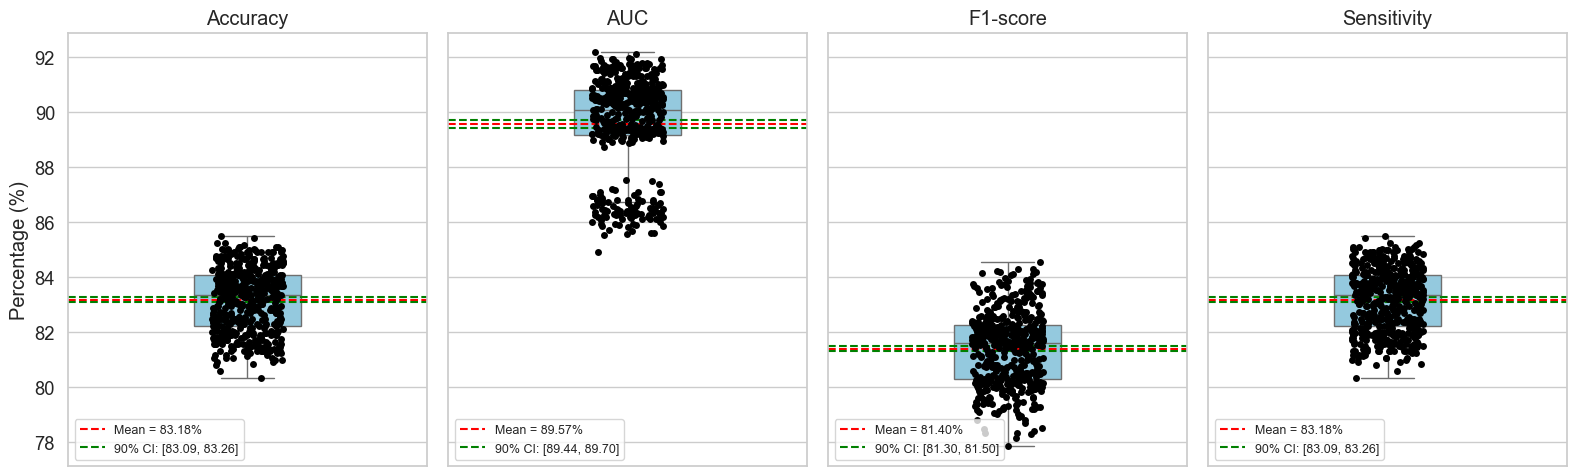


 Best model saved as: best_model_5fold_4Classes.keras


In [55]:
def mean_ci(values, ci=1.96):
    mean = np.mean(values)
    std = np.std(values)
    return mean, std / np.sqrt(len(values)) * ci

# Confidence Interval from scikit-learn
def confidence_interval(values, confidence=0.90):
    mean = np.mean(values)
    std = np.std(values)
    n = len(values)
    margin = 1.645 * std / np.sqrt(n)  # 90% CI
    return mean, mean - margin, mean + margin

X = np.concatenate([
    A_array_loaded[:, (0, 4, 19, 20)],
    B_array_loaded[:, (0, 4, 19, 20)],
    C_array_loaded[:, (0, 4, 19, 20)],
    D_array_loaded[:, (0, 4, 19, 20)]
], axis=0)

y = np.array(
    [0]*len(A_array_loaded) +
    [1]*len(B_array_loaded) +
    [2]*len(C_array_loaded) +
    [3]*len(D_array_loaded)
)

# Scale features
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

# Setup for 3 runs × 5 fold
kfold = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
accs_all, aucs_all, f1s_all, sens_all = [], [], [], []
best_auc = -1
best_model = None

for run in range(1, 101):
    print(f"\n========================")
    print(f"   RUN {run}/100")
    print(f"========================")

    for fold, (train_idx, test_idx) in enumerate(kfold.split(X_scaled, y), 1):
        X_train, X_test = X_scaled[train_idx], X_scaled[test_idx]
        y_train, y_test = y[train_idx], y[test_idx]

        y_train_cat = to_categorical(y_train, num_classes=4)
        y_test_cat = to_categorical(y_test, num_classes=4)

        # Model definition
        model = models.Sequential([
            layers.Input(shape=(X_train.shape[1],)),
            layers.Dense(16, activation='relu'),
            layers.Dense(4, activation='softmax')
        ])

        model.compile(
            optimizer='adam',
            loss=focal_loss(alpha=0.46, gamma=2.0),
            metrics=['accuracy']
        )

        model.fit(
            X_train, y_train_cat,
            validation_data=(X_test, y_test_cat),
            epochs=20,
            batch_size=8,
            verbose=0
        )

        # Predict
        y_pred_proba = model.predict(X_test, verbose=0)
        y_pred = np.argmax(y_pred_proba, axis=1)

        # Metrics
        acc = accuracy_score(y_test, y_pred)
        auc = roc_auc_score(y_test, y_pred_proba, multi_class='ovr')
        f1 = f1_score(y_test, y_pred, average='weighted')
        sensitivity = recall_score(y_test, y_pred, average='weighted')

        accs_all.append(acc)
        aucs_all.append(auc)
        f1s_all.append(f1)
        sens_all.append(sensitivity)

        print(f"Run {run} | Fold {fold}: ACC={acc:.3f}, AUC={auc:.3f}, F1={f1:.3f}, SEN={sensitivity:.3f}")

        if auc > best_auc:
            best_auc = auc
            best_model = model
            model.save("best_model_5fold_2_Classes.keras")
#Convert to arrays
accs_all, aucs_all, f1s_all, sens_all = map(np.array, [accs_all, aucs_all, f1s_all, sens_all])

metrics = {
    "Accuracy": accs_all,
    "AUC": aucs_all,
    "F1-score": f1s_all,
    "Sensitivity": sens_all
}

# Visualization
sns.set(style="whitegrid", font_scale=1.2)
fig, axes = plt.subplots(1, 4, figsize=(16, 5), sharey=True)

for i, (name, values) in enumerate(metrics.items()):
    mean, low, high = confidence_interval(values)
    ax = axes[i]

    sns.boxplot(y=values * 100, ax=ax, color="skyblue", width=0.3, fliersize=0)
    sns.stripplot(y=values * 100, ax=ax, color="black", size=5, jitter=0.1)

    ax.axhline(mean * 100, color="red", linestyle="--", label=f"Mean = {mean*100:.2f}%")
    ax.axhline(low * 100, color="green", linestyle="--", label=f"90% CI: [{low*100:.2f}, {high*100:.2f}]")
    ax.axhline(high * 100, color="green", linestyle="--")

    ax.set_title(name)
    ax.set_xlabel('')
    ax.set_ylabel('Percentage (%)')
    ax.legend(loc='lower left', fontsize=9)

plt.tight_layout()
plt.show()

print("\n Best model saved as: best_model_5fold_4Classes.keras")


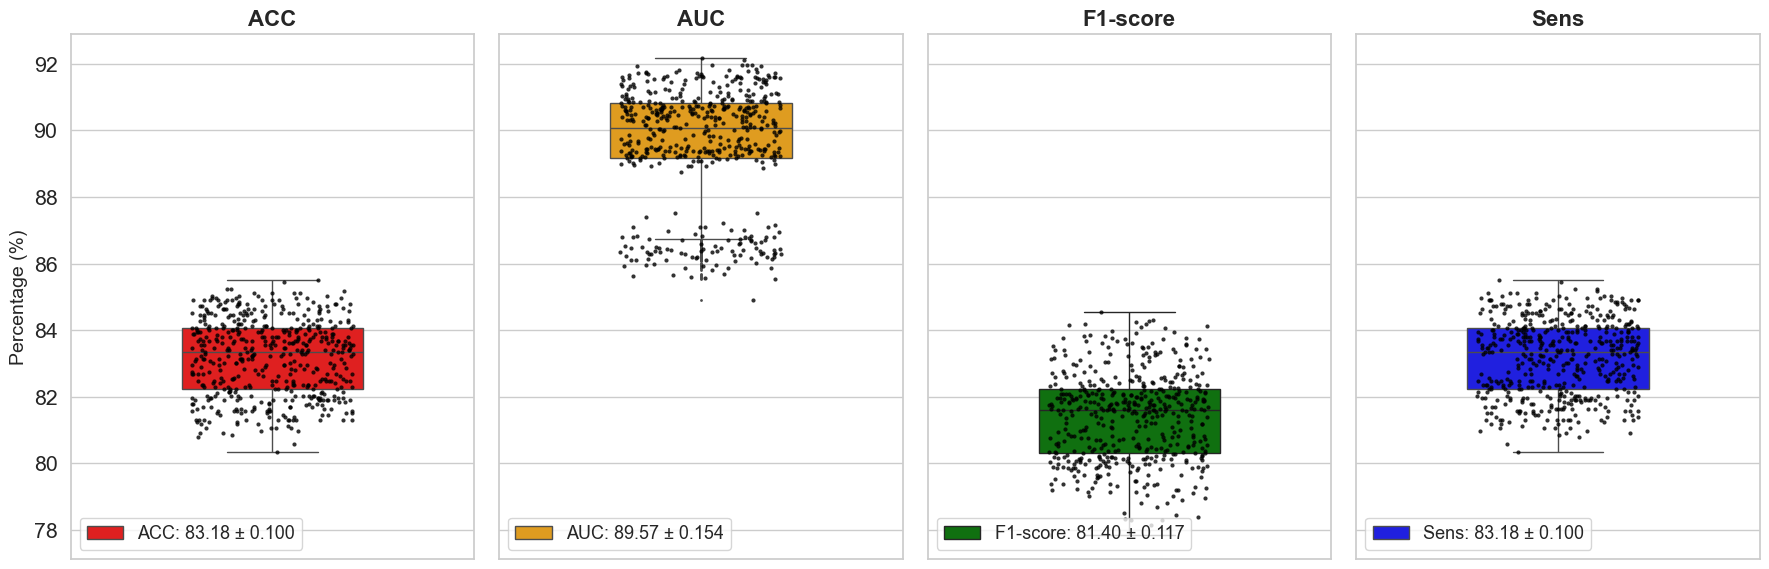

In [56]:
# Function for 95% Confidence-Interval
def confidence_interval(data, confidence=0.95):
    data = np.array(data)
    n = len(data)
    mean = np.mean(data)
    sem = stats.sem(data)
    h = sem * stats.t.ppf((1 + confidence) / 2, n - 1)
    return mean, h 

metrics = {"ACC": accs_all, "AUC": aucs_all, "F1-score": f1s_all, "Sens": sens_all}


sns.set(style="whitegrid", font_scale=1.4)
fig, axes = plt.subplots(1, 4, figsize=(18, 6), sharey=True)
colors = ("red", "orange", "green", "blue")
for i, (name, values) in enumerate(metrics.items()):
    mean, margin = confidence_interval(values)
    ax = axes[i]

    # Boxplot
    sns.boxplot(y=values * 100, ax=ax, color=colors[i], width=0.45, fliersize=1)

    # Small black points
    sns.stripplot(
        y=values * 100,
        ax=ax,
        color="black",
        alpha=0.8,
        size=3,
        jitter=0.2
    )

    # Legend
    ax.legend(
        [f"{name}: {mean*100:.2f} ± {margin*100:.3f}"],
        loc='lower left',
        fontsize=13,
        frameon=True
    )

    ax.set_title(name, fontsize=16, fontweight='bold')
    ax.set_xlabel('')
    ax.set_ylabel('Percentage (%)', fontsize=14)

plt.tight_layout()
plt.show()

## AB|CD


   RUN 1/100
Run 1 | Fold 1: ACC=0.935, AUC=0.939, F1=0.933, SEN=0.970
Run 1 | Fold 2: ACC=0.944, AUC=0.946, F1=0.940, SEN=0.982
Run 1 | Fold 3: ACC=0.947, AUC=0.947, F1=0.942, SEN=0.986
Run 1 | Fold 4: ACC=0.936, AUC=0.956, F1=0.931, SEN=0.981
Run 1 | Fold 5: ACC=0.942, AUC=0.945, F1=0.939, SEN=0.980

   RUN 2/100
Run 2 | Fold 1: ACC=0.946, AUC=0.948, F1=0.944, SEN=0.978
Run 2 | Fold 2: ACC=0.945, AUC=0.945, F1=0.942, SEN=0.981
Run 2 | Fold 3: ACC=0.944, AUC=0.950, F1=0.940, SEN=0.984
Run 2 | Fold 4: ACC=0.943, AUC=0.959, F1=0.940, SEN=0.978
Run 2 | Fold 5: ACC=0.940, AUC=0.947, F1=0.937, SEN=0.978

   RUN 3/100
Run 3 | Fold 1: ACC=0.942, AUC=0.947, F1=0.936, SEN=0.984
Run 3 | Fold 2: ACC=0.948, AUC=0.944, F1=0.942, SEN=0.988
Run 3 | Fold 3: ACC=0.947, AUC=0.949, F1=0.942, SEN=0.988
Run 3 | Fold 4: ACC=0.940, AUC=0.954, F1=0.935, SEN=0.980
Run 3 | Fold 5: ACC=0.941, AUC=0.945, F1=0.938, SEN=0.977

   RUN 4/100
Run 4 | Fold 1: ACC=0.944, AUC=0.946, F1=0.941, SEN=0.979
Run 4 | Fold 2: 

Run 24 | Fold 1: ACC=0.939, AUC=0.942, F1=0.937, SEN=0.974
Run 24 | Fold 2: ACC=0.943, AUC=0.945, F1=0.939, SEN=0.981
Run 24 | Fold 3: ACC=0.943, AUC=0.949, F1=0.939, SEN=0.981
Run 24 | Fold 4: ACC=0.938, AUC=0.959, F1=0.934, SEN=0.977
Run 24 | Fold 5: ACC=0.940, AUC=0.942, F1=0.934, SEN=0.986

   RUN 25/100
Run 25 | Fold 1: ACC=0.936, AUC=0.943, F1=0.935, SEN=0.970
Run 25 | Fold 2: ACC=0.946, AUC=0.951, F1=0.943, SEN=0.983
Run 25 | Fold 3: ACC=0.944, AUC=0.945, F1=0.942, SEN=0.976
Run 25 | Fold 4: ACC=0.940, AUC=0.959, F1=0.932, SEN=0.987
Run 25 | Fold 5: ACC=0.942, AUC=0.945, F1=0.938, SEN=0.980

   RUN 26/100
Run 26 | Fold 1: ACC=0.940, AUC=0.947, F1=0.939, SEN=0.973
Run 26 | Fold 2: ACC=0.944, AUC=0.949, F1=0.942, SEN=0.976
Run 26 | Fold 3: ACC=0.947, AUC=0.948, F1=0.944, SEN=0.981
Run 26 | Fold 4: ACC=0.939, AUC=0.958, F1=0.935, SEN=0.980
Run 26 | Fold 5: ACC=0.938, AUC=0.944, F1=0.936, SEN=0.971

   RUN 27/100
Run 27 | Fold 1: ACC=0.940, AUC=0.945, F1=0.938, SEN=0.973
Run 27 | Fo

Run 47 | Fold 1: ACC=0.944, AUC=0.947, F1=0.939, SEN=0.984
Run 47 | Fold 2: ACC=0.947, AUC=0.947, F1=0.941, SEN=0.990
Run 47 | Fold 3: ACC=0.946, AUC=0.947, F1=0.939, SEN=0.990
Run 47 | Fold 4: ACC=0.938, AUC=0.956, F1=0.936, SEN=0.974
Run 47 | Fold 5: ACC=0.944, AUC=0.945, F1=0.940, SEN=0.981

   RUN 48/100
Run 48 | Fold 1: ACC=0.940, AUC=0.948, F1=0.940, SEN=0.967
Run 48 | Fold 2: ACC=0.942, AUC=0.946, F1=0.937, SEN=0.985
Run 48 | Fold 3: ACC=0.943, AUC=0.945, F1=0.941, SEN=0.975
Run 48 | Fold 4: ACC=0.940, AUC=0.957, F1=0.935, SEN=0.980
Run 48 | Fold 5: ACC=0.946, AUC=0.946, F1=0.942, SEN=0.981

   RUN 49/100
Run 49 | Fold 1: ACC=0.942, AUC=0.945, F1=0.940, SEN=0.973
Run 49 | Fold 2: ACC=0.946, AUC=0.946, F1=0.942, SEN=0.983
Run 49 | Fold 3: ACC=0.948, AUC=0.950, F1=0.944, SEN=0.983
Run 49 | Fold 4: ACC=0.940, AUC=0.959, F1=0.935, SEN=0.983
Run 49 | Fold 5: ACC=0.937, AUC=0.940, F1=0.926, SEN=0.992

   RUN 50/100
Run 50 | Fold 1: ACC=0.934, AUC=0.945, F1=0.933, SEN=0.968
Run 50 | Fo

Run 70 | Fold 1: ACC=0.942, AUC=0.947, F1=0.941, SEN=0.970
Run 70 | Fold 2: ACC=0.946, AUC=0.946, F1=0.941, SEN=0.984
Run 70 | Fold 3: ACC=0.946, AUC=0.948, F1=0.942, SEN=0.983
Run 70 | Fold 4: ACC=0.941, AUC=0.957, F1=0.937, SEN=0.979
Run 70 | Fold 5: ACC=0.939, AUC=0.945, F1=0.933, SEN=0.984

   RUN 71/100
Run 71 | Fold 1: ACC=0.942, AUC=0.947, F1=0.938, SEN=0.978
Run 71 | Fold 2: ACC=0.949, AUC=0.947, F1=0.945, SEN=0.984
Run 71 | Fold 3: ACC=0.946, AUC=0.947, F1=0.943, SEN=0.978
Run 71 | Fold 4: ACC=0.942, AUC=0.957, F1=0.939, SEN=0.978
Run 71 | Fold 5: ACC=0.944, AUC=0.944, F1=0.939, SEN=0.985

   RUN 72/100
Run 72 | Fold 1: ACC=0.941, AUC=0.946, F1=0.939, SEN=0.973
Run 72 | Fold 2: ACC=0.944, AUC=0.946, F1=0.938, SEN=0.988
Run 72 | Fold 3: ACC=0.947, AUC=0.943, F1=0.943, SEN=0.983
Run 72 | Fold 4: ACC=0.940, AUC=0.959, F1=0.937, SEN=0.976
Run 72 | Fold 5: ACC=0.942, AUC=0.941, F1=0.939, SEN=0.978

   RUN 73/100
Run 73 | Fold 1: ACC=0.941, AUC=0.945, F1=0.937, SEN=0.981
Run 73 | Fo

Run 93 | Fold 1: ACC=0.938, AUC=0.945, F1=0.934, SEN=0.976
Run 93 | Fold 2: ACC=0.950, AUC=0.947, F1=0.947, SEN=0.981
Run 93 | Fold 3: ACC=0.948, AUC=0.949, F1=0.943, SEN=0.986
Run 93 | Fold 4: ACC=0.940, AUC=0.957, F1=0.935, SEN=0.983
Run 93 | Fold 5: ACC=0.942, AUC=0.944, F1=0.940, SEN=0.977

   RUN 94/100
Run 94 | Fold 1: ACC=0.941, AUC=0.946, F1=0.939, SEN=0.975
Run 94 | Fold 2: ACC=0.945, AUC=0.948, F1=0.939, SEN=0.987
Run 94 | Fold 3: ACC=0.945, AUC=0.947, F1=0.942, SEN=0.980
Run 94 | Fold 4: ACC=0.941, AUC=0.954, F1=0.937, SEN=0.979
Run 94 | Fold 5: ACC=0.938, AUC=0.944, F1=0.932, SEN=0.983

   RUN 95/100
Run 95 | Fold 1: ACC=0.938, AUC=0.944, F1=0.930, SEN=0.989
Run 95 | Fold 2: ACC=0.951, AUC=0.950, F1=0.948, SEN=0.985
Run 95 | Fold 3: ACC=0.945, AUC=0.948, F1=0.942, SEN=0.981
Run 95 | Fold 4: ACC=0.942, AUC=0.957, F1=0.940, SEN=0.975
Run 95 | Fold 5: ACC=0.940, AUC=0.944, F1=0.933, SEN=0.987

   RUN 96/100
Run 96 | Fold 1: ACC=0.939, AUC=0.947, F1=0.939, SEN=0.968
Run 96 | Fo

ValueError: too many values to unpack (expected 2)

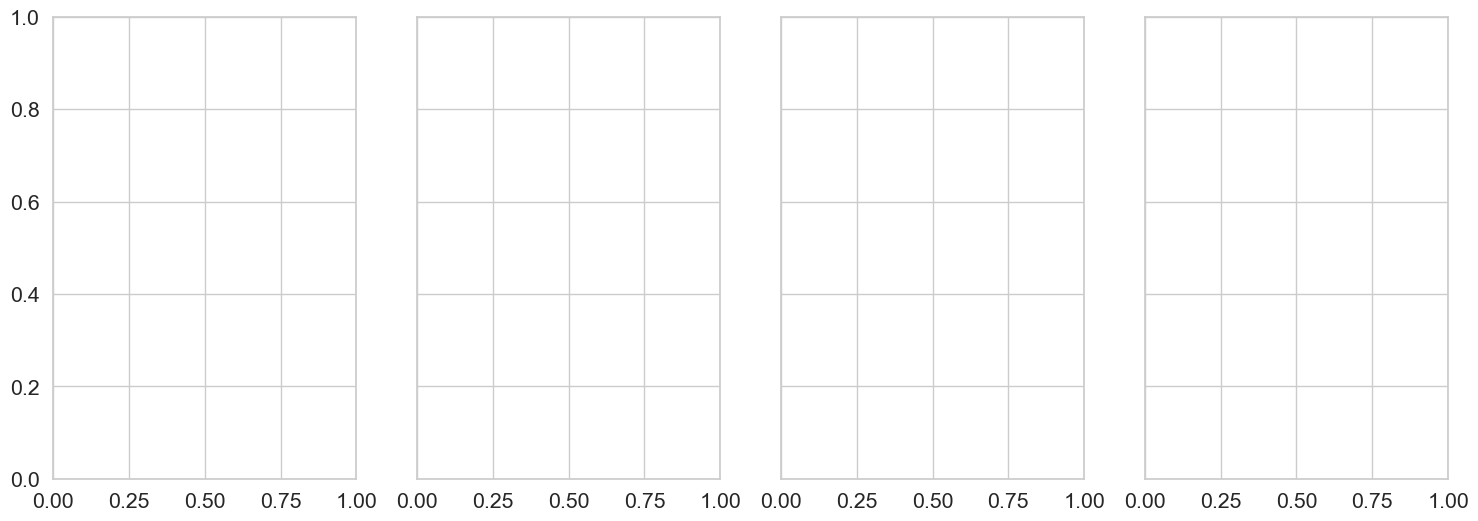

In [61]:
from tensorflow.keras.utils import to_categorical
from sklearn.model_selection import StratifiedKFold
from sklearn.metrics import accuracy_score, roc_auc_score, f1_score, confusion_matrix
from sklearn.metrics import recall_score

X = np.concatenate([
    A_array_loaded[:, (0, 4, 19, 20)],
    B_array_loaded[:, (0, 4, 19, 20)],
    C_array_loaded[:, (0, 4, 19, 20)],
    D_array_loaded[:, (0, 4, 19, 20)]
], axis=0)

y = np.array(
    [0]*(len(A_array_loaded) + len(B_array_loaded)) +
    [1]*(len(C_array_loaded) + len(D_array_loaded))
)

# Scale
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

kfold = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

accs_all, aucs_all, f1s_all, sens_all = [], [], [], []

for run in range(1, 101):
    print(f"\n========================")
    print(f"   RUN {run}/100")
    print(f"========================")

    accs, aucs, f1s, sens = [], [], [], []

    for fold, (train_idx, test_idx) in enumerate(kfold.split(X_scaled, y), 1):
        X_train, X_test = X_scaled[train_idx], X_scaled[test_idx]
        y_train, y_test = y[train_idx], y[test_idx]

        y_train_cat = to_categorical(y_train, num_classes=2)
        y_test_cat = to_categorical(y_test, num_classes=2)

        model = models.Sequential([
            layers.Input(shape=(X_train.shape[1],)),
            layers.Dense(16, activation='relu'),
            layers.Dense(2, activation='softmax')
        ])

        #Adam
        model.compile(
            optimizer='adam',
            loss=focal_loss(alpha=0.46, gamma=2.0),
            metrics=['accuracy']
        )

        model.fit(
            X_train, y_train_cat,
            validation_data=(X_test, y_test_cat),
            epochs=20,
            batch_size=8,
            verbose=0
        )

        # Predicted comp
        y_pred_proba = model.predict(X_test, verbose=0)
        y_pred = np.argmax(y_pred_proba, axis=1)

        ## metrics of performance///
        acc = accuracy_score(y_test, y_pred)
        auc = roc_auc_score(y_test, y_pred_proba[:, 1])
        f1 = f1_score(y_test, y_pred, average='weighted')

        cm = confusion_matrix(y_test, y_pred)
        tn, fp, fn, tp = cm.ravel()
        sensitivity = tp / (tp + fn) if (tp + fn) > 0 else 0

        accs.append(acc)
        aucs.append(auc)
        f1s.append(f1)
        sens.append(sensitivity)

        print(f"Run {run} | Fold {fold}: ACC={acc:.3f}, AUC={auc:.3f}, F1={f1:.3f}, SEN={sensitivity:.3f}")

    accs_all.extend(accs)
    aucs_all.extend(aucs)
    f1s_all.extend(f1s)
    sens_all.extend(sens)

accs_all1, aucs_all1, f1s_all1, sens_all1 = map(np.array, [accs_all, aucs_all, f1s_all, sens_all])

metrics = {"Accuracy": accs_all1, "AUC": aucs_all1, "F1-score": f1s_all1, "Sensitivity": sens_all1}

sns.set(style="whitegrid", font_scale=1.4)
fig, axes = plt.subplots(1, 4, figsize=(18, 6), sharey=True)

for i, (name, values) in enumerate(metrics.items()):
    mean, margin = confidence_interval(values)
    ax = axes[i]

    # Boxplot
    sns.boxplot(y=values * 100, ax=ax, color="skyblue", width=0.3, fliersize=0)

    sns.stripplot(
        y=values * 100,
        ax=ax,
        color="black",
        alpha=0.4,
        size=3,
        jitter=0.1
    )

    ax.legend(
        [f"{name}: {mean*100:.2f} ± {margin*100:.2f}"],
        loc='lower left',
        fontsize=13,
        frameon=True
    )

    ax.set_title(name, fontsize=16, fontweight='bold')
    ax.set_xlabel('')
    ax.set_ylabel('Percentage (%)', fontsize=14)

plt.tight_layout()
plt.show()


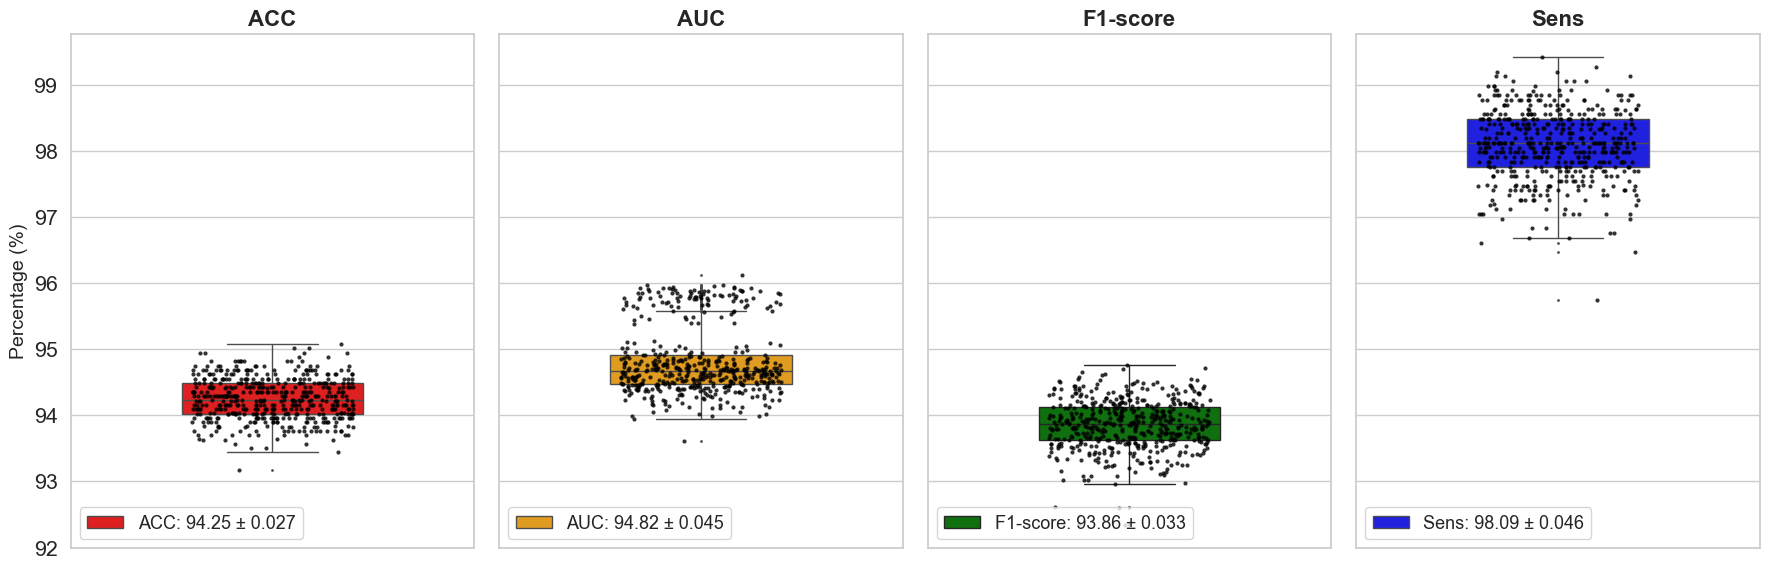

In [62]:
metrics = {"ACC": accs_all1, "AUC": aucs_all1, "F1-score": f1s_all1, "Sens": sens_all1}


sns.set(style="whitegrid", font_scale=1.4)
fig, axes = plt.subplots(1, 4, figsize=(18, 6), sharey=True)
colors = ("red", "orange", "green", "blue")
for i, (name, values) in enumerate(metrics.items()):
    mean, margin = confidence_interval(values)
    ax = axes[i]

    sns.boxplot(y=values * 100, ax=ax, color=colors[i], width=0.45, fliersize=1)

    sns.stripplot(
        y=values * 100,
        ax=ax,
        color="black",
        alpha=0.8,
        size=3,
        jitter=0.2
    )

    ax.legend(
        [f"{name}: {mean*100:.2f} ± {margin*100:.3f}"],
        loc='lower left',
        fontsize=13,
        frameon=True
    )

    ax.set_title(name, fontsize=16, fontweight='bold')
    ax.set_xlabel('')
    ax.set_ylabel('Percentage (%)', fontsize=14)

plt.tight_layout()
plt.show()

## AB|C|D

In [66]:
#

In [67]:

X = np.concatenate([
    A_array_loaded[:, (0, 4, 19, 20)],
    B_array_loaded[:, (0, 4, 19, 20)],
    C_array_loaded[:, (0, 4, 19, 20)],
    D_array_loaded[:, (0, 4, 19, 20)]
], axis=0)

y = np.array(
    [0]*(len(A_array_loaded) + len(B_array_loaded)) +
    [1]*len(C_array_loaded) +
    [2]*len(D_array_loaded)
)


scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

kfold = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
accs_all, aucs_all, f1s_all, sens_all = [], [], [], []
best_auc = -1
best_model = None

for run in range(1, 101):

    for fold, (train_idx, test_idx) in enumerate(kfold.split(X_scaled, y), 1):
        X_train, X_test = X_scaled[train_idx], X_scaled[test_idx]
        y_train, y_test = y[train_idx], y[test_idx]

        y_train_cat = to_categorical(y_train, num_classes=3)
        y_test_cat = to_categorical(y_test, num_classes=3)

        # Model definition
        model = models.Sequential([
            layers.Input(shape=(X_train.shape[1],)),
            layers.Dense(16, activation='relu'),
            layers.Dense(3, activation='softmax')
        ])

        model.compile(
            optimizer='adam',
            loss=focal_loss(alpha=0.46, gamma=2.0),
            metrics=['accuracy']
        )

        model.fit(
            X_train, y_train_cat,
            validation_data=(X_test, y_test_cat),
            epochs=20,
            batch_size=8,
            verbose=0
        )

        y_pred_proba = model.predict(X_test, verbose=0)
        y_pred = np.argmax(y_pred_proba, axis=1)

        # Metrics
        acc = accuracy_score(y_test, y_pred)
        auc = roc_auc_score(y_test, y_pred_proba, multi_class='ovr')
        f1 = f1_score(y_test, y_pred, average='weighted')
        sensitivity = recall_score(y_test, y_pred, average='weighted')

        accs_all.append(acc)
        aucs_all.append(auc)
        f1s_all.append(f1)
        sens_all.append(sensitivity)


        if auc > best_auc:
            best_auc = auc
            best_model = model
            model.save("best_model_5fold_3Classes.keras")
accs_all, aucs_all, f1s_all, sens_all = map(np.array, [accs_all, aucs_all, f1s_all, sens_all])

metrics = {
    "Accuracy": accs_all,
    "AUC": aucs_all,
    "F1-score": f1s_all,
    "Sensitivity": sens_all
}


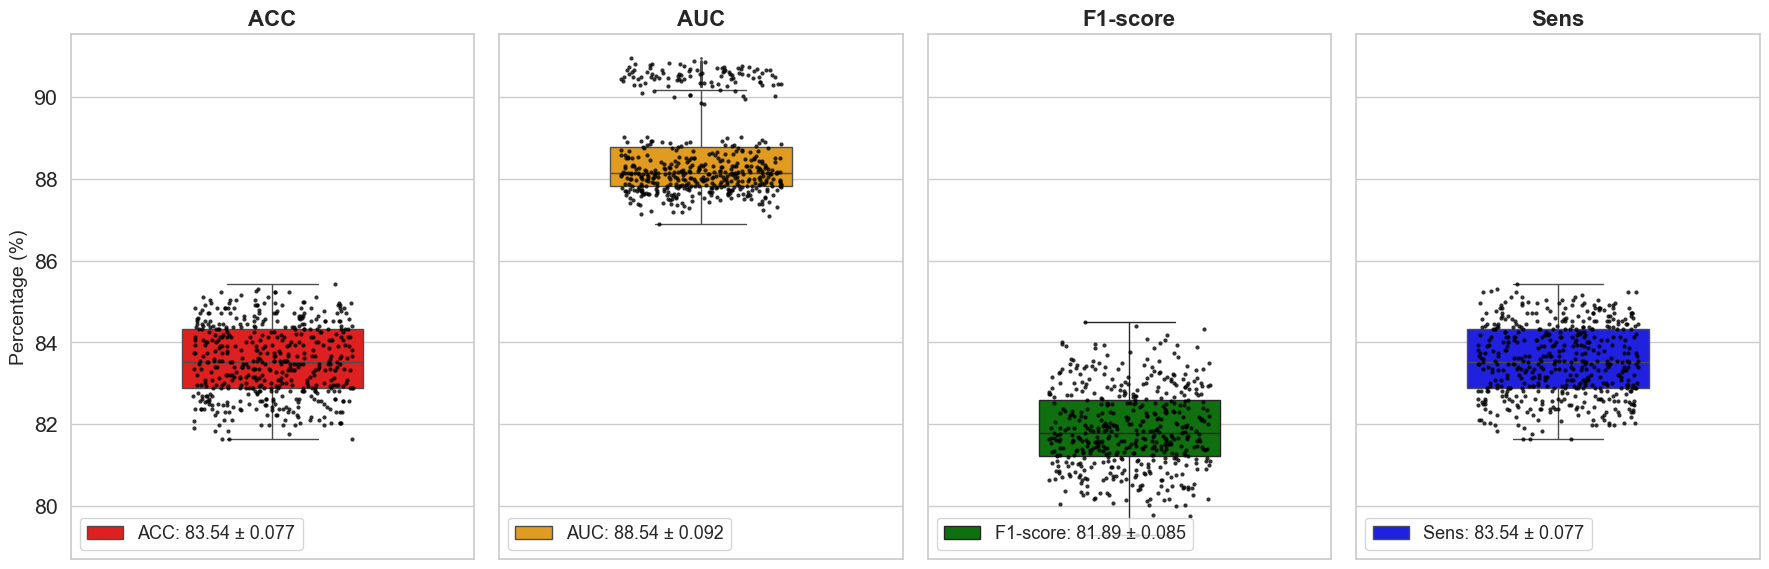

In [68]:
metrics = {"ACC": accs_all, "AUC": aucs_all, "F1-score": f1s_all, "Sens": sens_all}


sns.set(style="whitegrid", font_scale=1.4)
fig, axes = plt.subplots(1, 4, figsize=(18, 6), sharey=True)
colors = ("red", "orange", "green", "blue")
for i, (name, values) in enumerate(metrics.items()):
    mean, margin = confidence_interval(values)
    ax = axes[i]

    sns.boxplot(y=values * 100, ax=ax, color=colors[i], width=0.45, fliersize=1)

    sns.stripplot(
        y=values * 100,
        ax=ax,
        color="black",
        alpha=0.8,
        size=3,
        jitter=0.2
    )

    ax.legend(
        [f"{name}: {mean*100:.2f} ± {margin*100:.3f}"],
        loc='lower left',
        fontsize=13,
        frameon=True
    )

    ax.set_title(name, fontsize=16, fontweight='bold')
    ax.set_xlabel('')
    ax.set_ylabel('Percentage (%)', fontsize=14)

plt.tight_layout()
plt.show()